# 03 — Doublet detection

Doublet detection should be run with `nf-scdoublet` (Nextflow pipeline, methods: Scrublet + Solo).  

This notebook:
1. Inspects the doublet score distributions from both methods
2. Builds a pre-removal UMAP and overlays doublet scores to validate calls visually
3. Removes predicted doublets
4. Saves the clean object for downstream analysis

---
## Step 0 — Imports

In [1]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path

import os
import scipy.io
import scanpy as sc
import anndata as ad
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

sc.settings.verbosity = 2  # show INFO messages from scanpy
sc.settings.set_figure_params(dpi=100, facecolor="white")

print(f"scanpy  version: {sc.__version__}")
print(f"anndata version: {ad.__version__}")
print(f"pandas  version: {pd.__version__}")
print(f"numpy   version: {np.__version__}")

from besca_sc import filter_cells_and_genes, subset_adata, qc
from besca_sc import get_threshold, calculate_thresholds
from besca_sc import plot_thresholds
from besca_sc.paths import (
    EXTERNAL_DIR,
    INTERIM_DIR,
    PROCESSED_DIR,
    RAW_DIR,
    RESULTS_DIR,
)

scanpy  version: 1.12.4
anndata version: 0.13.4
pandas  version: 3.0.6
numpy   version: 2.5.4


/var/folders/22/sjkvvcj17_gdnvz15k1nj1800000gn/T/ipykernel_21820/3760991807.py:15: FutureWarning: The method set_figure_params is deprecated and will be removed in the future. Use :func:`scanpy.set_figure_params` instead
  sc.settings.set_figure_params(dpi=100, facecolor="white")
/var/folders/22/sjkvvcj17_gdnvz15k1nj1800000gn/T/ipykernel_21820/3760991807.py:17: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print(f"scanpy  version: {sc.__version__}")
/var/folders/22/sjkvvcj17_gdnvz15k1nj1800000gn/T/ipykernel_21820/3760991807.py:18: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  print(f"anndata version: {ad.__version__}")


---
## Step 1 — Load doublet-scored AnnData

In [2]:
adata = sc.read_h5ad(f"{PROCESSED_DIR}/initial_qc_merged.doublets.h5ad")
print(adata)
print(f"\n{adata.n_obs} cells  x  {adata.n_vars} genes")

# Map SOLO prediction back to boolean
adata.obs['solo_prediction'] = adata.obs['solo_prediction'].map({'doublet': True, 'singlet': False}).astype(bool)

print("\nDoublet-related obs columns:")
doublet_cols = ['scrublet_score', 'scrublet_predicted_doublet', 'solo_doublet_probability', 'solo_prediction']
print(adata.obs[doublet_cols].head())

AnnData object with n_obs × n_vars = 21870 × 38606
    obs: 'htodemux_Assignment', 'multiseq_Assignment', 'hasheddrops_Assignment', 'gmmdemux_Assignment', 'hashsolo_Assignment', 'bff_consensuscall_Assignment', 'demuxmix_Assignment', 'Consensus_Assignment', 'Confidence', 'Consensus_DropletType', 'Donor', 'stimulation', 'library', 'sample_id', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'scrublet_score', 'scrublet_predicted_doublet', 'solo_doublet_probability', 'solo_prediction'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: 'doublet_detection', 'sample_id_colors'
    layers: 'counts', None (.X)

21870 cells  x  38606 genes

Doublet-related obs columns:
                             scrublet_score  scrublet_predicted_doublet  \
TACTTGTCACAAAGTA-1-Infected        0.039692                       False   
CCACACTCACAGTCAT-1-Infected        0.035517                       Fal

---
## Step 2 — Inspect doublet score distributions

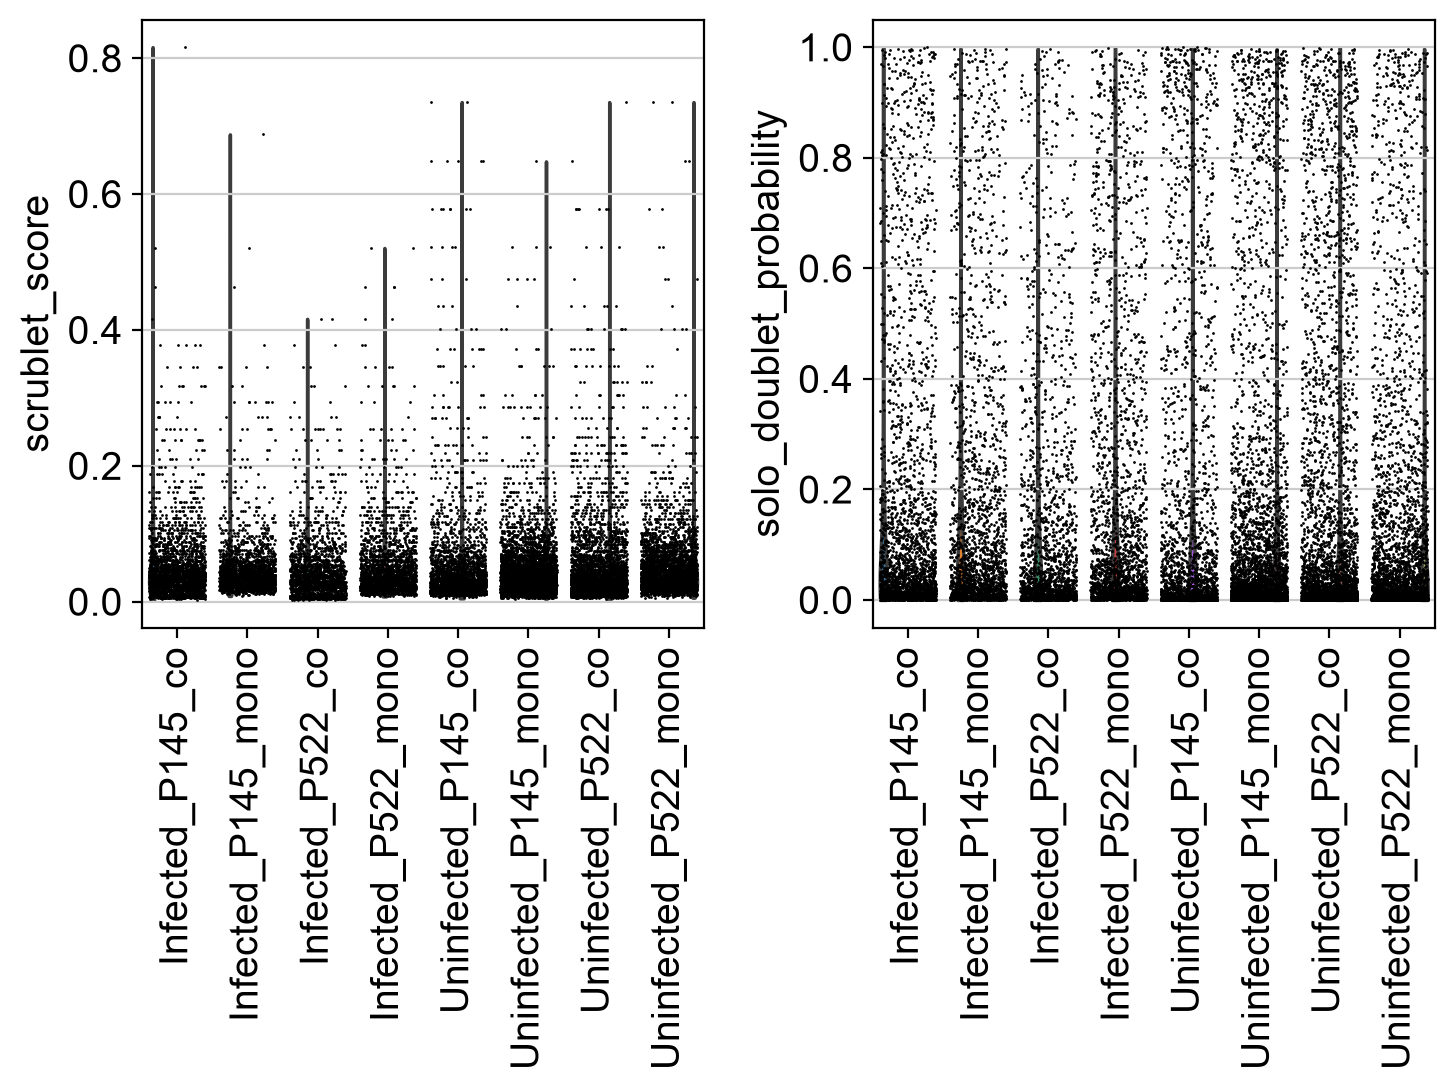

In [3]:
# Violin plots after filtering — confirm the distributions look cleaner
sc.pl.violin(
    adata,
    keys=["scrublet_score", "solo_doublet_probability"],
    groupby="sample_id",
    rotation=90,
    jitter=0.4,
    multi_panel=True,
)

In [4]:
# Doublet counts per sample_id for each method
print("=== Scrublet doublets per sample_id ===")
print(adata.obs.groupby('sample_id')['scrublet_predicted_doublet'].sum().to_string())
print()
print("=== Solo doublets per sample_id ===")
print((adata.obs['solo_prediction'] == 'doublet').groupby(adata.obs['sample_id']).sum().to_string())

=== Scrublet doublets per sample_id ===
sample_id
Infected_P145_co        1
Infected_P145_mono      1
Infected_P522_co        0
Infected_P522_mono      0
Uninfected_P145_co      2
Uninfected_P145_mono    0
Uninfected_P522_co      1
Uninfected_P522_mono    2

=== Solo doublets per sample_id ===
sample_id
Infected_P145_co        0
Infected_P145_mono      0
Infected_P522_co        0
Infected_P522_mono      0
Uninfected_P145_co      0
Uninfected_P145_mono    0
Uninfected_P522_co      0
Uninfected_P522_mono    0


---
## Step 3 — Build pre-removal UMAP

We compute the UMAP on all cells (including predicted doublets) and overlay the doublet scores.  
Genuine doublets should appear between clusters or in small isolated clusters with mixed marker expression.  

In [5]:
# Work on a copy so raw counts are preserved in adata.X for filtering later
adata_pp = adata.copy()

# Normalise and log-transform
sc.pp.normalize_total(adata_pp)
sc.pp.log1p(adata_pp)

# Select highly variable genes (per-library to reduce batch effects)
sc.pp.highly_variable_genes(adata_pp, n_top_genes=2000, batch_key='library')
print(f"Highly variable genes: {adata_pp.var['highly_variable'].sum()}")

# PCA on HVGs
sc.pp.pca(adata_pp, use_highly_variable=True)

# Neighbourhood graph and UMAP
sc.pp.neighbors(adata_pp, n_pcs=30)
sc.tl.umap(adata_pp)

# Transfer UMAP coordinates back to adata so we don't need to recompute
adata.obsm['X_umap'] = adata_pp.obsm['X_umap']
adata.obsm['X_pca']  = adata_pp.obsm['X_pca']

print("UMAP done.")

normalizing counts per cell
    finished (0:00:02)
extracting highly variable genes
    finished (0:00:05)
Highly variable genes: 2000
computing PCA
    with n_comps=50


/var/folders/22/sjkvvcj17_gdnvz15k1nj1800000gn/T/ipykernel_21820/1599883451.py:13: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  sc.pp.pca(adata_pp, use_highly_variable=True)


    finished (0:00:01)
computing neighbors
    using 'X_pca' with n_pcs = 30
    finished (0:00:18)
computing UMAP
    finished (0:00:10)
UMAP done.


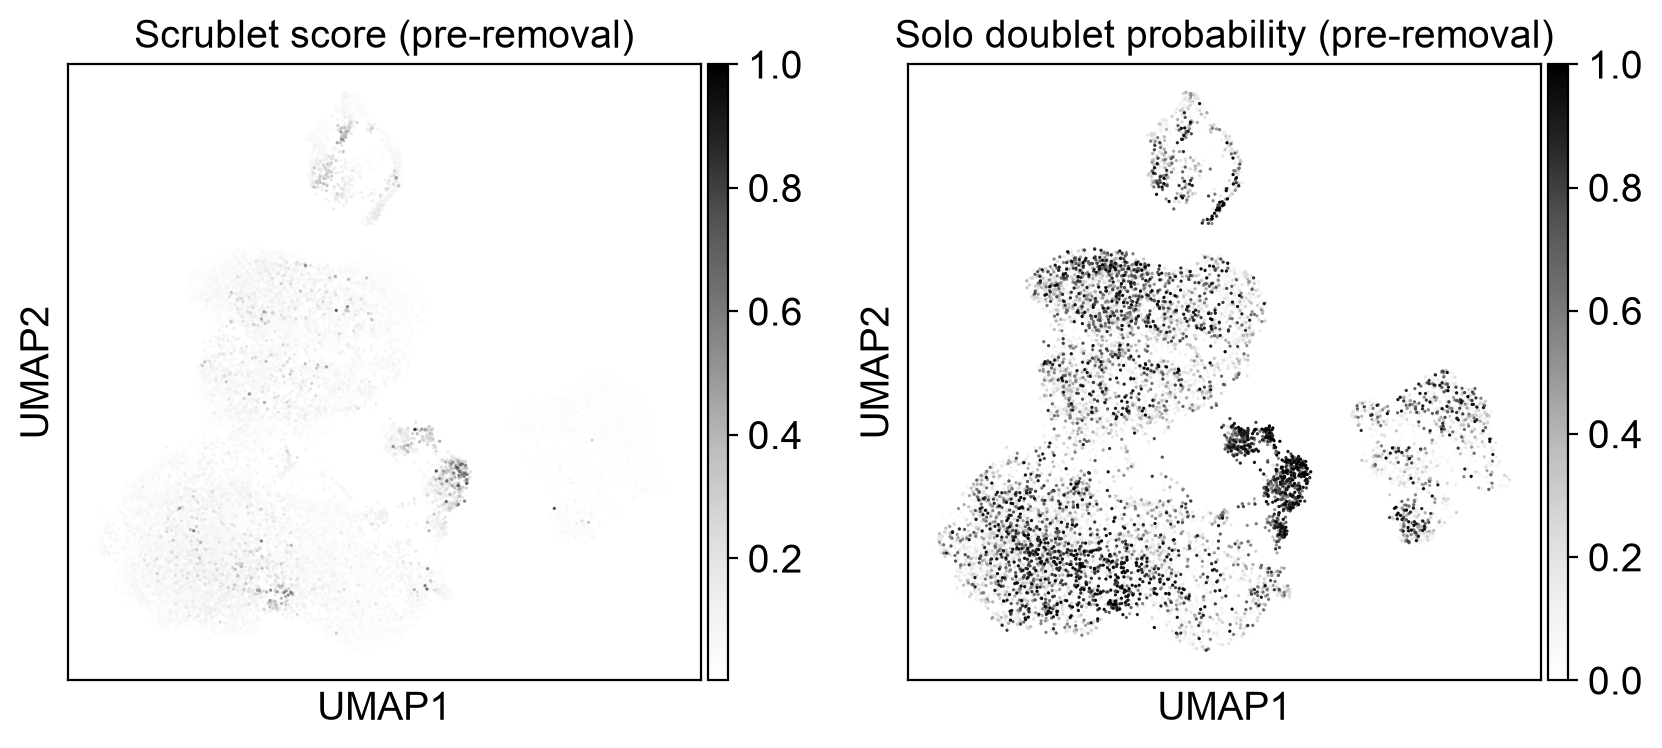

In [6]:
# Overlay boolean decision on UMAP
sc.pl.umap(
    adata_pp,
    color=['scrublet_score', 'solo_doublet_probability'],
    ncols=2,
    cmap='Greys',
    vmax=[1.0, 1.0, None, None],
    title=[
        'Scrublet score (pre-removal)',
        'Solo doublet probability (pre-removal)'
    ]
)

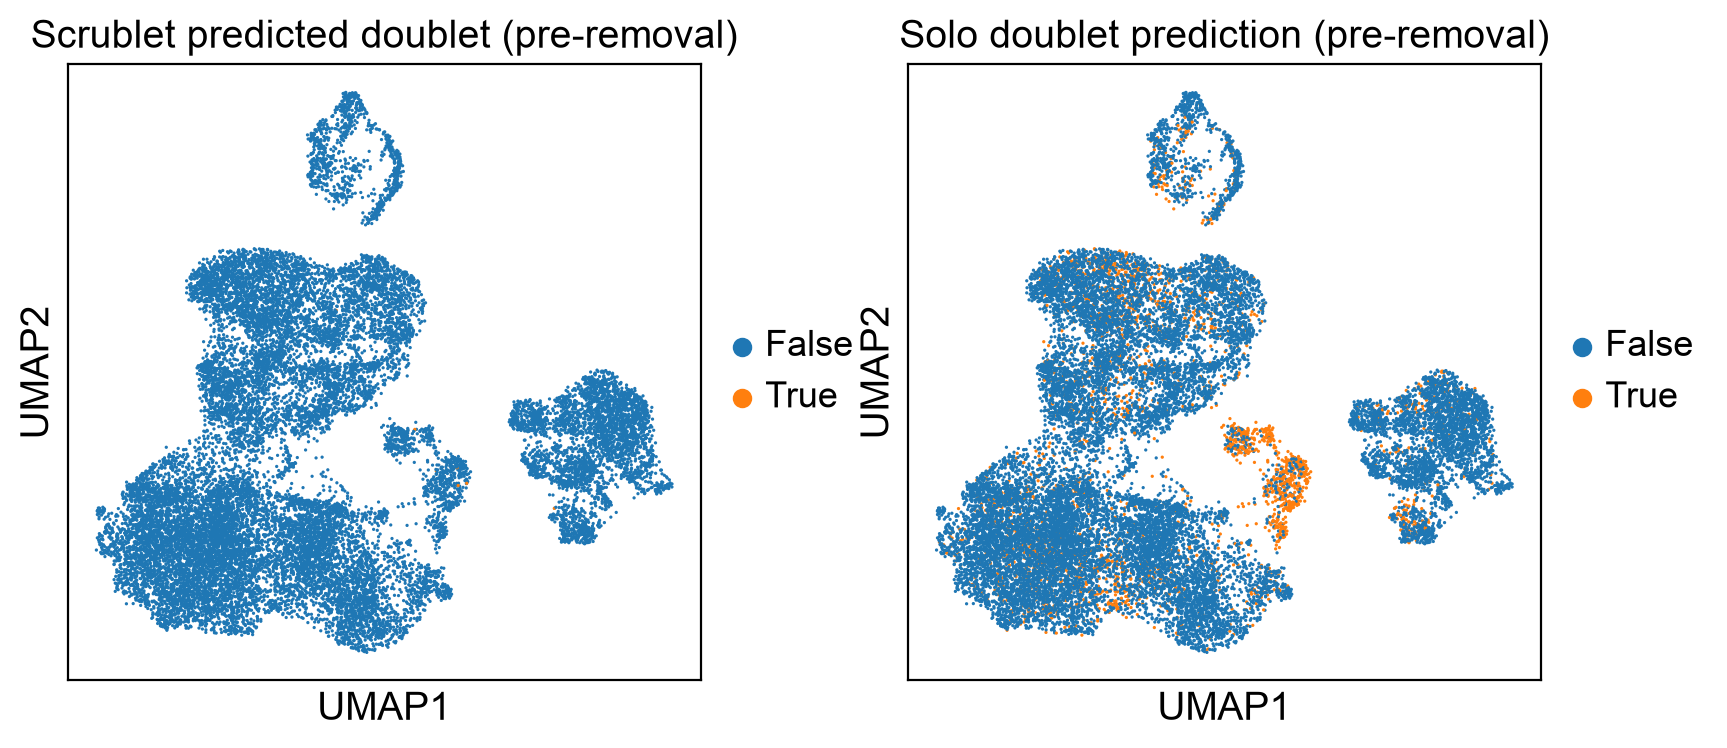

In [7]:
# Overlay doublet de on UMAP
sc.pl.umap(
    adata_pp,
    color=['scrublet_predicted_doublet', 'solo_prediction'],
    ncols=2,
    title=[
        'Scrublet predicted doublet (pre-removal)',
        'Solo doublet prediction (pre-removal)'
    ]
)

---
## Step 4 — Flag doublets

In [8]:
# ─────────────────────────────────────────────────────────────────────────────

# Flag cells which were predicted to be doublets based on either method
adata.obs['is_doublet'] = (adata.obs['scrublet_predicted_doublet']) | (adata.obs['solo_prediction'])

print(f"Doublets flagged: {adata.obs['is_doublet'].sum()} ({adata.obs['is_doublet'].mean()*100:.1f}%)")
print()
print("Doublets per library:")
print(adata.obs.groupby('library')['is_doublet'].agg(['sum', 'mean']).rename(columns={'sum': 'n_doublets', 'mean': 'frac'}).round(3).to_string())

Doublets flagged: 2952 (13.5%)

Doublets per library:
            n_doublets   frac
library                      
Infected          1191  0.143
Uninfected        1761  0.130


In [9]:
# Write out the post-doublet calling AnnData object and explore in cellxgene
out_path = f"{PROCESSED_DIR}/doublet_called.h5ad"
adata.write_h5ad(out_path)
print(f"Saved: {out_path}")
print(f"  {adata.n_obs} cells  x  {adata.n_vars} genes")

Saved: /Users/adaml9/besca_sc/data/processed/doublet_called.h5ad
  21870 cells  x  38606 genes
